# Tutorial 6: Developing mouse brain (E11.0–E18.5, MISAR-seq)

Integrate chromatin accessibility profiles from four developing mouse brain sections to identify spatial domains and compare their spatial organization across developmental stages. This example uses combined ATAC counts with shared peak IDs, section IDs and native coordinates; tissue annotations support reference plots. No RNA or motif matrix is used.

**Original study.** [Jiang et al., Nature Methods (2023)](https://doi.org/10.1038/s41592-023-01884-1); [NODE OEP003285](https://www.biosino.org/node/project/detail/OEP003285).

**Output provenance.** The numerical outputs are retained from the completed 500-epoch run.


## 1. Environment and configuration

Follow the [installation guide](../docs/installation.rst). The supplied `Embryo_multislice_adaptive_depth_gate.json` profile specifies 500 training epochs and a target of 16 domains. The target is a downstream analysis setting; `DATASET` names the run independently of the selected profile.

Set the count, output and optional annotation paths and inspect the parameter dictionaries below. For new data, name every section in `TRAINING_OPTIONS["slice_shards"]` and select the matching `slice_key`. Set `ANNOTATIONS_PATH` and `ANNOTATION_PALETTE_PATH` to `None` when reference labels are unavailable; they support display and post-fit interpretation.

Choose `RUN_MODE="train"` for model training or `RUN_MODE="provided"` to analyze selected saved embeddings. Provided mode skips count filtering, network preparation and model training. Rerun from this setup cell after changing inputs or settings.

For new data, clear the example display frame after `DISPLAY_OPTIONS` is created:

```python
DISPLAY_OPTIONS["spatial_transforms"] = {}
DISPLAY_OPTIONS["spatial_bounds"] = None
DISPLAY_OPTIONS["slice_titles"] = {}
```

These options transform plotted coordinate copies. Native coordinates remain the model inputs. `SEAREG_PHYSICAL_GPU` selects a CUDA card; CPU training requires `TRAINING_OPTIONS["device"]="cpu"`, `EXECUTION_OPTIONS["physical_gpu"]=None` and an unset `SEAREG_PHYSICAL_GPU`.


In [1]:
from pathlib import Path
from dataclasses import asdict
import json
import os
import sys
import time
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "seareg/__init__.py").is_file() and (p / "tutorials/configs").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "tutorials"))
import seareg as sr
from seareg_tutorial_data import prepare_input_file, create_run_directory, file_sha256
from seareg_tutorial_embeddings import load_tutorial_embeddings
from seareg_tutorial_multislice import (
    load_annotations, annotation_palette, match_domain_palette, spatial_panels,
)

PROFILE_PATH = ROOT / "tutorials/configs/Embryo_multislice_adaptive_depth_gate.json"
profile = json.loads(PROFILE_PATH.read_text())
DATASET = "Embryo_multislice"
RUN_MODE = "train"  # "train" or "provided"; rerun from here after changing inputs.
ATAC_PATH = (PROFILE_PATH.parent / profile["input"]["atac"]).resolve()
ANNOTATIONS_PATH = (PROFILE_PATH.parent / profile["input"]["annotations"]).resolve()
ANNOTATION_PALETTE_PATH = (PROFILE_PATH.parent / profile["input"]["annotation_palette"]).resolve()
EMBEDDING_DIR = (PROFILE_PATH.parent / profile["selected_model"]["provided_export"]).resolve()
OUTPUT_DIR = ROOT / "result" / DATASET
REOPEN_ANALYSIS_PATH = None  # Optional explicit saved analysis for step 16.
TRAINING_OPTIONS = dict(profile["training"])
ANALYSIS_OPTIONS = dict(profile["analysis"])
EXECUTION_OPTIONS = dict(profile["execution"]) if RUN_MODE == "train" else {
    "physical_gpu": None, "torch_threads": 1, "torch_interop_threads": 1,
    "blas_threads": 1, "strict_algorithms": True, "tf32": False,
}
DISPLAY_OPTIONS = dict(profile["display"])
approved_palette_setting = DISPLAY_OPTIONS.get("approved_domain_palette")
APPROVED_DOMAIN_PALETTE_PATH = ((PROFILE_PATH.parent / approved_palette_setting).resolve()
                                if approved_palette_setting else None)
if RUN_MODE not in ("train", "provided"):
    raise ValueError("RUN_MODE must be train or provided")
if RUN_MODE == "train" and "SEAREG_PHYSICAL_GPU" in os.environ:
    EXECUTION_OPTIONS["physical_gpu"] = int(os.environ["SEAREG_PHYSICAL_GPU"])
training_config = sr.MultiSliceConfig(**TRAINING_OPTIONS)
analysis_config = sr.AnalysisConfig(**ANALYSIS_OPTIONS)
print("SEAREG:", sr.__version__)
print("Dataset / mode:", DATASET, RUN_MODE)
print("Selected correction:", training_config.correction_mode)
if RUN_MODE == "train":
    print("Training device / physical GPU:", training_config.device, EXECUTION_OPTIONS["physical_gpu"])
    print("Epochs / section shards:", training_config.epochs, training_config.slice_shards)


SEAREG: 1.0.0
Dataset / mode: Embryo_multislice train
Selected correction: adaptive_depth_gate
Training device / physical GPU: cuda:0 2
Epochs / section shards: 500 {'E11_0-S1': 10, 'E13_5-S1': 10, 'E15_5-S1': 20, 'E18_5-S1': 20}


## 2. Prepare inputs and reserve a new run

Resolve the selected counts and reserve a unique run directory for this execution. In provided mode, validate and load the selected embedding exports before reserving that directory.

The run directory keeps the analysis, figures and execution receipt together; input hashes identify the counts used by the workflow.


In [2]:
ATAC_PATH = prepare_input_file(ATAC_PATH, bundle_root=ROOT)
input_hashes = {str(ATAC_PATH): file_sha256(ATAC_PATH)}
OUTPUT_DIR = Path(OUTPUT_DIR).expanduser().resolve()
provided_embeddings = None
if RUN_MODE == "provided":
    EMBEDDING_DIR = Path(EMBEDDING_DIR).expanduser().resolve()
    provided_embeddings = load_tutorial_embeddings(EMBEDDING_DIR, counts_path=ATAC_PATH)
RUN_DIR = create_run_directory(ROOT, DATASET, RUN_MODE, output=OUTPUT_DIR)
stage_seconds = {}
notebook_started = time.perf_counter()
filtered_counts = network = training_inputs = training_job = training_run = None
print("Run:", RUN_DIR)
print("Input SHA256:", input_hashes)


Run: source://train_20261031T114218Z_f0f0e6ee/result/Embryo_multislice/runs/train_20261031T114218Z_f0f0e6ee
Input SHA256: {'source://train_20261031T114218Z_f0f0e6ee/data/Embryo_multislice/counts.h5ad': '3e12a3257747adfc045186b75d588fca85d6d07f52bf929cfccd428dedb5f745'}


## 3. Inspect counts, sections and spatial coordinates

Preview the spot-by-peak counts and native coordinates, then summarize the number of spots in each section. Check the spot IDs, shared peak IDs and section labels that will identify observations throughout the analysis.

The next cell displays the available tissue annotations on these coordinates.


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

counts = ad.read_h5ad(ATAC_PATH, backed="r")
try:
    print(counts)
    spot_ids = tuple(counts.obs_names.astype(str))
    slice_ids = tuple(counts.obs[training_config.slice_key].astype(str))
    spatial_coordinates = pd.DataFrame(np.asarray(counts.obsm["spatial"])[:, :2], columns=["x", "y"])
    spatial_coordinates.insert(0, "spot_id", spot_ids)
    counts_shape = tuple(counts.shape)
    matrix = counts.X
    if getattr(matrix, "format", None) == "csr":
        block = matrix[np.arange(counts.n_obs) < 5, :5]
    elif getattr(matrix, "format", None) == "csc":
        block = matrix[:5, np.arange(counts.n_vars) < 5]
    else:
        block = matrix[:5, :5]
    values = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
    display(pd.DataFrame(values, index=counts.obs_names[:5], columns=counts.var_names[:5]))
    display(spatial_coordinates.head())
finally:
    counts.file.close()
del counts, matrix, block, values
slice_order = list(dict.fromkeys(slice_ids))
reference_layout = all(section in DISPLAY_OPTIONS["spatial_transforms"] for section in slice_order)
spatial_display = {
    "marker": DISPLAY_OPTIONS["spatial_marker"],
    "point_size": DISPLAY_OPTIONS["spatial_point_size"],
    "display_transforms": {section: DISPLAY_OPTIONS["spatial_transforms"].get(
        section, [[1, 0, 0], [0, 1, 0]]) for section in slice_order},
    "slice_titles": DISPLAY_OPTIONS["slice_titles"],
    "display_bounds": DISPLAY_OPTIONS["spatial_bounds"] if reference_layout else None,
}
cohort_table = pd.Series(slice_ids).value_counts(sort=False).rename_axis("sample_id").rename("spots").to_frame()
cohort_table["shards"] = [training_config.slice_shards.get(section) for section in cohort_table.index]
display(cohort_table)
print(f"Counts: {counts_shape[0]:,} spots x {counts_shape[1]:,} peaks")


AnnData object with n_obs × n_vars = 7118 × 120380 backed at 'source://train_20261031T114218Z_f0f0e6ee/data/Embryo_multislice/counts.h5ad'
    obs: 'barcode', 'sample_id', 'time', 'section', 'array_col', 'array_row', 'fragment_records', 'fragments'
    var: 'seqnames', 'start', 'end', 'width', 'n_supporting_slices', 'supported_E11_0_S1', 'supported_E13_5_S1', 'supported_E15_5_S1', 'supported_E18_5_S1'
    uns: 'additional_spot_filtering', 'counting_strategy', 'feature_definition', 'genome', 'peak_calling_strategy', 'samples', 'spatial_graph_policy'
    obsm: 'spatial'


peak_id,chr1-3094781-3095285,chr1-3119670-3120170,chr1-3120219-3120719,chr1-3251270-3251770,chr1-3399698-3400198
cell_id,,,,,
E11_0-S1#GATCTTACTCCTACCA-1,0,0,0,0,0
E11_0-S1#ACCGCCAAACTCAATA-1,0,0,0,0,0
E11_0-S1#CTTGCGCCACTCAATA-1,0,0,0,0,0
E11_0-S1#TCGGCCTTGCCATTCT-1,0,0,0,0,0
E11_0-S1#AGAGCTATACTCAATA-1,0,0,0,0,0


,spot_id,x,y
0,E11_0-S1#GATCTTACTCCTACCA-1,27.0,22.0
1,E11_0-S1#ACCGCCAAACTCAATA-1,46.0,21.0
2,E11_0-S1#CTTGCGCCACTCAATA-1,37.0,21.0
3,E11_0-S1#TCGGCCTTGCCATTCT-1,39.0,17.0
4,E11_0-S1#AGAGCTATACTCAATA-1,32.0,21.0


,spots,shards
sample_id,,
E11_0-S1,1263,10
E13_5-S1,1777,10
E15_5-S1,1949,20
E18_5-S1,2129,20


Counts: 7,118 spots x 120,380 peaks


### 3.1 Display reference annotations

Join the tissue annotations to spot IDs and draw a reference map for each section. The accompanying count table shows annotation composition and missing labels; Unknown spots remain in the model and figures.

Counts, section IDs and coordinates supply the model inputs. Tissue labels provide reference context and later post-fit display colors.


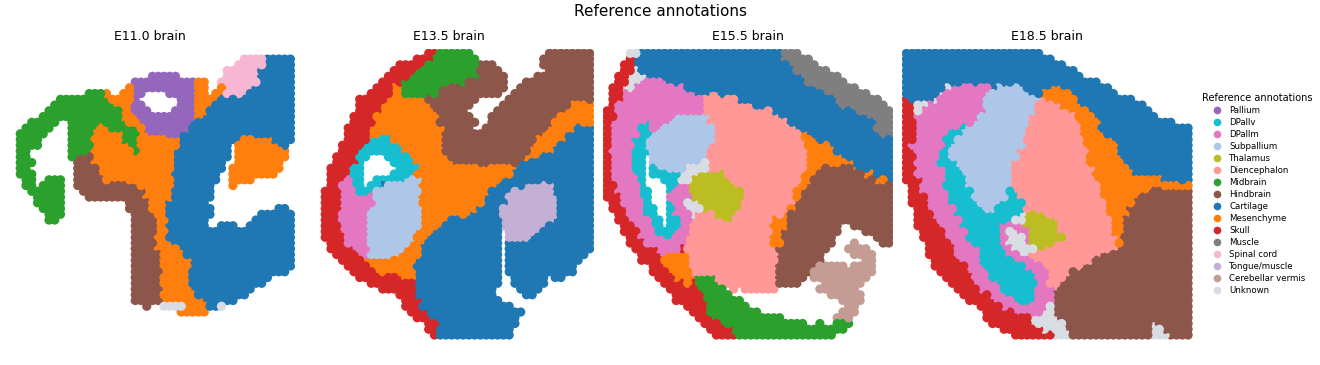

spots
sample_id annotation              
E11_0-S1  Cartilage            533
          Hindbrain            133
          Mesenchyme           306
          Midbrain             167
          Pallium               82
          Spinal cord           37
          Unknown                5
E13_5-S1  Cartilage            582
          DPallm                56
          DPallv                55
          Hindbrain            325
          Mesenchyme           326
          Midbrain              70
          Skull                183
          Subpallium           103
          Tongue/muscle         77
E15_5-S1  Cartilage            364
          Cerebellar vermis     73
          DPallm               207
          DPallv                59
          Diencephalon         441
          Hindbrain            242
          Mesenchyme            80
          Midbrain             108
          Muscle                82
          Skull                119
          Subpallium            90
          Thalamus              58
          Unknown               26
E18_5-S1  Cartilage            392
          DPallm               247
          DPallv               160
          Diencephalon         328
          Hindbrain            440
          Mesenchyme           138
          Skull                151
          Subpallium           192
          Thalamus              31
          Unknown               50

In [4]:
from seareg import plotting
from matplotlib import pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", bbox_inches=None)

if ANNOTATIONS_PATH is None:
    annotations = pd.DataFrame({"spot_id": spot_ids, "sample_id": slice_ids,
                                "annotation": "Unknown"})
else:
    ANNOTATIONS_PATH = Path(ANNOTATIONS_PATH).expanduser().resolve()
    annotations = load_annotations(ANNOTATIONS_PATH, spot_ids, slice_ids)
reference_palette = annotation_palette(annotations, ANNOTATION_PALETTE_PATH,
                                       unknown_color="#D8DDE3")
annotation_display = annotations.rename(columns={"annotation": "domain"})
figures = {}
fig, axes = spatial_panels(spatial_coordinates, slice_ids, annotation_display,
                           palette=reference_palette, title="Reference annotations",
                           slice_order=slice_order, **spatial_display)
figures["reference_annotations"] = fig
display(fig, metadata={"image/png": {"width": 900}})
plt.close(fig)
display(annotations.groupby(["sample_id", "annotation"]).size().rename("spots").to_frame())

## 4. Filter the count matrix

Retain chromosome peaks meeting section-wise minimum prevalence in at least
one section, then apply the global maximum-prevalence cap. Save counts, axes
and coordinates as `MultiSliceFilteredCounts`. This is the joint-section
filter described in the [multislice guide](../docs/multislice.rst).


In [5]:
if RUN_MODE == "train":
    if file_sha256(ATAC_PATH) != input_hashes[str(ATAC_PATH)]:
        raise ValueError("Counts changed after input validation")
    started = time.perf_counter()
    filtered_counts = sr.filter_multislice_counts(ATAC_PATH, training_config, RUN_DIR / "filtered")
    stage_seconds["filter_counts"] = time.perf_counter() - started
    if file_sha256(ATAC_PATH) != input_hashes[str(ATAC_PATH)]:
        raise ValueError("Counts changed during filtering")
    print("Filtered shape:", filtered_counts.metadata["shape"])
    print("Retained shared peaks:", len(filtered_counts.peak_ids))
    print("Filtered fingerprint:", filtered_counts.fingerprint)
else:
    print("Skipped in provided mode; the selected embeddings were validated in step 2.")


Filtered shape: (7118, 120380)
Retained shared peaks: 120380
Filtered fingerprint: 93366a200a2bd8f54930f715b500986c9d97af2feaa2b940cec8a302c8f40d6a


## 5. Record the motif-free stage

This model uses spots and shared peaks. It skips the motif preparation stage
used by T1–T5.


In [6]:
selected_motif = None
print("Motif-free multislice model: spots and shared peaks only.")


Motif-free multislice model: spots and shared peaks only.


## 6. Build the multislice network

Build and save the spot–peak graph on the shared peak axis together with a spatial graph for each section. Shared peak nodes support comparison in one model, while each section keeps its own spatial-neighbor graph.

Inspect the directional-coverage table and `spatial_coverage.json` to assess whether the saved graph and native coordinate units support the additional correction term. Spots without all four unit-cardinal directions receive no extra displacement-budget term.


In [7]:
if RUN_MODE == "train":
    started = time.perf_counter()
    network = sr.build_multislice_network(filtered_counts, training_config, RUN_DIR / "network")
    stage_seconds["build_network"] = time.perf_counter() - started
    data = network.load_data()
    display(pd.DataFrame([{"entity": "spots", "nodes": len(data.spot_ids)},
                          {"entity": "shared peaks", "nodes": len(data.peak_ids)}]))
    print("Spot–peak positives:", data.X.nnz)
    print("Network fingerprint:", network.fingerprint)
    display(pd.DataFrame([dict(row) for row in network.metadata["graph_report"]]))
    from seareg.multislice.geometry import spatial_coverage_report
    spatial_graph = network.load_graphs()["spatial"]
    slice_codes, section_names = pd.factorize(pd.Index(data.slice_ids), sort=True)
    coverage_report = spatial_coverage_report(data.coordinates, spatial_graph, slice_codes)
    for row in coverage_report["per_slice"]:
        row["sample_id"] = str(section_names[row["slice_code"]])
    (RUN_DIR / "spatial_coverage.json").write_text(
        json.dumps(coverage_report, indent=2), encoding="utf-8")
    display(pd.DataFrame(coverage_report["per_slice"]).set_index("sample_id"))
    print("Coverage uses native coordinates and the saved graph; unit cardinal distance=1, tolerance=1e-6.")
    print("Missing cardinal support gives zero extra microgain; geometry alone does not establish valid donors.")
    del data, spatial_graph
else:
    print("Skipped in provided mode; no training network was built.")


,entity,nodes
0,spots,7118
1,shared peaks,120380


Spot–peak positives: 53013448
Network fingerprint: b04523cdac268a8ae13b4c4092397f38a2531d193b020cace8b4597b5415d82f


,sample_id,spots,positive_edges,spatial_edges
0,E11_0-S1,1263,6120079,50436
1,E13_5-S1,1777,11013673,76232
2,E15_5-S1,1949,19743838,83162
3,E18_5-S1,2129,16135858,95064


,slice_code,spots,eight_sector_covered,eight_sector_fraction,cardinal_covered,cardinal_fraction
sample_id,,,,,,
E11_0-S1,0,1263,973,0.770388,1014,0.802850
E13_5-S1,1,1777,1520,0.855374,1558,0.876759
E15_5-S1,2,1949,1665,0.854284,1689,0.866598
E18_5-S1,3,2129,1933,0.907938,1962,0.921559


Coverage uses native coordinates and the saved graph; unit cardinal distance=1, tolerance=1e-6.
Missing cardinal support gives zero extra microgain; geometry alone does not establish valid donors.


## 7. Prepare training inputs and inspect the protocol

In train mode, prepare the sampler inputs from the saved network. The adaptive gate combines local deviations in detected-peak counts and molecular messages to reduce the influence of depth-associated outliers during spot–peak propagation.

The training-input fingerprint identifies the prepared graph and sampling configuration passed to the job. The protocol table shows the selected sampling, optimizer, refresh and save settings in both modes. See the [multislice protocol](../docs/multislice.rst) for correction and loss definitions.


In [8]:
if RUN_MODE == "train":
    started = time.perf_counter()
    training_inputs = sr.prepare_multislice_training(network, training_config, RUN_DIR / "training_inputs")
    stage_seconds["prepare_training"] = time.perf_counter() - started
    print("Training-input fingerprint:", training_inputs.fingerprint)
    print("Data fingerprint:", training_inputs.metadata["data_fingerprint"])
else:
    print("Skipped in provided mode; no training inputs were prepared.")

protocol = pd.Series({
    "correction_mode": training_config.correction_mode,
    "epochs": training_config.epochs,
    "embedding_dimensions": training_config.hidden_dim,
    "seed": training_config.seed,
    "Adam_steps_per_epoch": training_config.updates_per_epoch,
    "loss_propagations_per_epoch": training_config.updates_per_epoch * len(training_config.slice_shards),
    "weight_per_section": 1 / len(training_config.slice_shards),
    "negatives_per_positive": training_config.pn_r,
    "reshard_every": training_config.reshard_every,
    "negative_refresh": training_config.negative_refresh,
    "gate_and_geometry_refresh": training_config.gate_refresh_every,
    "rolling_checkpoint_every": training_config.checkpoint_every,
    "full_export_start": training_config.export_start_epoch,
    "full_export_every": training_config.export_every,
}, name="Selected protocol")
display(protocol.to_frame())


Training-input fingerprint: 09fbff7105df8ac3b61a14d22487e845b4b5b3fe17bf8a4a6ba100997af38ae2
Data fingerprint: 8b29870169b4682511e9ca764458f6c5bd0cc110d0229e75f6e19c74653c08b3


,Selected protocol
correction_mode,adaptive_depth_gate
epochs,500
embedding_dimensions,64
seed,1234
Adam_steps_per_epoch,20
loss_propagations_per_epoch,80
weight_per_section,0.25
negatives_per_positive,5
reshard_every,100
negative_refresh,5


## 8. Initialize and train SEAREG

In train mode, submit the prepared inputs to an independent training job and wait for its completed model. The final epoch, optimizer updates and training history document the optimization that produced the embeddings used next.

Provided mode performs no training. Runtime records and recovery instructions remain with each training job; see [training and recovery](../docs/workflow.rst).


In [9]:
if RUN_MODE == "train":
    from seareg_tutorial_display import single_line_multislice_training_progress
    started = time.perf_counter()
    training_job = sr.start_multislice_training_job(
        training_inputs, training_config, RUN_DIR / "training",
        execution=EXECUTION_OPTIONS, name=DATASET + "_adaptive_depth_gate")
    print("Independent training job:", training_job.path)
    print("Recovery and logs:", training_job.path / "TRAINING_HANDOFF.md")
    with single_line_multislice_training_progress(total=training_config.epochs):
        training_run = training_job.wait()
    stage_seconds["training_process"] = time.perf_counter() - started
    training_metadata = training_run.manifest["metadata"]
    print("Final epoch / optimizer updates:", training_run.final_epoch, training_metadata["optimizer_steps"])
    print("Training process seconds:", stage_seconds["training_process"])
    history = pd.read_csv(training_run.path / "training_history.tsv", sep="\t")
    print("Last epoch backend counts:", history.iloc[-1]["backend_counts"])
    display(history.tail())
else:
    training_metadata = None
    stage_seconds["training_process"] = None
    print("Provided mode: preparation and training were skipped.")


Independent training job: source://train_20261031T114218Z_f0f0e6ee/result/Embryo_multislice/runs/train_20261031T114218Z_f0f0e6ee/training_job
Recovery and logs: source://train_20261031T114218Z_f0f0e6ee/result/Embryo_multislice/runs/train_20261031T114218Z_f0f0e6ee/training_job/TRAINING_HANDOFF.md


100%|██████████| 500/500 [46:04<00:00,  5.53s/it]

Final epoch / optimizer updates: 500 10000
Training process seconds: 2766.744980607007
Last epoch backend counts: {'cuda_fused': 80}


,epoch,completed_epoch,optimizer_steps,propagation_steps,loss,bpr,reg,per_slice,selected_shards,group_slice_order,...,geometry_formula_version,geometry_epoch,valid_coverage_fraction,boundary_mean,receiver_gate_mean,micro_formula_version,micro_epoch,micro_alpha,micro_refresh_count,geometry_update_seconds
495,496,496,9920,80,0.230795,0.153956,76.838805,"{0: {'name': 'E11_0-S1', 'loss': 0.15856005251...","{0: [4, 3, 5, 7, 9, 0, 2, 6, 1, 8, 4, 0, 6, 3,...","[[3, 0, 1, 2], [0, 1, 2, 3], [1, 2, 3, 0], [2,...",...,2,450,0.855718,0.051537,0.105585,1,450,"[1.9168628568877466e-05, 7.117936911527067e-05...",10,0.521253
496,497,497,9940,80,0.230725,0.153831,76.894154,"{0: {'name': 'E11_0-S1', 'loss': 0.15851499289...","{0: [2, 6, 9, 3, 5, 1, 7, 0, 4, 8, 9, 4, 3, 8,...","[[0, 1, 2, 3], [1, 2, 3, 0], [2, 3, 0, 1], [3,...",...,2,450,0.855718,0.051537,0.105585,1,450,"[1.9168628568877466e-05, 7.117936911527067e-05...",10,0.521253
497,498,498,9960,80,0.230655,0.153706,76.949160,"{0: {'name': 'E11_0-S1', 'loss': 0.15846360549...","{0: [0, 5, 7, 6, 8, 4, 9, 2, 3, 1, 3, 4, 5, 6,...","[[1, 2, 3, 0], [2, 3, 0, 1], [3, 0, 1, 2], [0,...",...,2,450,0.855718,0.051537,0.105585,1,450,"[1.9168628568877466e-05, 7.117936911527067e-05...",10,0.521253
498,499,499,9980,80,0.230579,0.153575,77.003856,"{0: {'name': 'E11_0-S1', 'loss': 0.15841525942...","{0: [2, 3, 0, 5, 8, 6, 1, 4, 7, 9, 9, 5, 0, 1,...","[[2, 3, 0, 1], [3, 0, 1, 2], [0, 1, 2, 3], [1,...",...,2,450,0.855718,0.051537,0.105585,1,450,"[1.9168628568877466e-05, 7.117936911527067e-05...",10,0.521253
499,500,500,10000,80,0.230512,0.153454,77.058764,"{0: {'name': 'E11_0-S1', 'loss': 0.15837051197...","{0: [1, 2, 0, 5, 4, 7, 8, 6, 3, 9, 7, 3, 0, 9,...","[[3, 0, 1, 2], [0, 1, 2, 3], [1, 2, 3, 0], [2,...",...,2,500,0.855718,0.049206,0.104713,1,500,"[1.780056300049182e-05, 6.745167047483847e-05,...",11,0.483554


## 9. Load node embeddings

Load the propagated spot and shared-peak embeddings selected by `RUN_MODE`. Train mode uses the completed training job; provided mode uses the exports validated in step 2.

The source-evidence table identifies the origin and epoch of the embeddings passed to analysis.


In [10]:
embedding_source = training_run if RUN_MODE == "train" else EMBEDDING_DIR
embeddings = (load_tutorial_embeddings(embedding_source, counts_path=ATAC_PATH)
              if RUN_MODE == "train" else provided_embeddings)
EMBEDDING_DIR = Path(embeddings.provenance["export_path"])
entity_frames = {"spot": embeddings.spot, "peak": embeddings.peak}
display(pd.DataFrame({"entity": entity_frames.keys(),
                      "rows": [len(frame) for frame in entity_frames.values()]}))
print(f"Embedding source: {embeddings.provenance['embedding_origin']}; {EMBEDDING_DIR}")

display(pd.Series({"epoch": embeddings.provenance["epoch"],
                   "origin": embeddings.provenance["embedding_origin"],
                   "training_executed": embeddings.provenance["training_executed"],
                   "source_receipt": embeddings.provenance.get("reference"),
                   "export_sha256": embeddings.provenance["export_sha256"]},
                  name="Embedding source evidence").to_frame())

,entity,rows
0,spot,7118
1,peak,120380


Embedding source: new_training; source://train_20261031T114218Z_f0f0e6ee/result/Embryo_multislice/runs/train_20261031T114218Z_f0f0e6ee/training/embeddings/500_epoch


,Embedding source evidence
epoch,500
origin,new_training
training_executed,True
source_receipt,None
export_sha256,a572849801164d6708372e0bcf9b33ff2e734978be67ed...


## 10. Fit native exact-K domains and UMAPs

Fit spatial domains and spot/joint UMAPs from the selected embeddings. A spot-neighbor graph supports exact-K Louvain search and the spot UMAP; a separate joint fit contains all spots and shared peaks.

The analysis saves domain labels, the search trace, graphs and coordinates. Both train and provided modes fit this analysis. Step 16 loads its saved labels and coordinates for inspection without refitting.


In [11]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=1):
    result = sr.analyze(embeddings, analysis_config, RUN_DIR / "analysis", plots=False)
domain_result = result.domains() if analysis_config.domains else None
spot_result = result.spot_embedding() if analysis_config.spot_umap else None
joint_result = result.joint_embedding() if analysis_config.joint else None
if domain_result is not None:
    print(f"Observed spatial domains: {domain_result.observed_k}; target K: {analysis_config.target_domains}; native exact-K search")
    display(domain_result.labels.head())

Observed spatial domains: 16; target K: (16,); native exact-K search


,spot_id,slice_id,domain
0,E11_0-S1#GATCTTACTCCTACCA-1,E11_0-S1,D2
1,E11_0-S1#ACCGCCAAACTCAATA-1,E11_0-S1,D4
2,E11_0-S1#CTTGCGCCACTCAATA-1,E11_0-S1,D2
3,E11_0-S1#TCGGCCTTGCCATTCT-1,E11_0-S1,D2
4,E11_0-S1#AGAGCTATACTCAATA-1,E11_0-S1,D2


## 11. Select display colors

Build the display palette and mapping table used by the domain panels. Reuse the bundled display aliases when spot memberships match the saved partition; otherwise use annotation-based matching or fallback colors.

The table links native domain IDs to their displayed names and colors. This presentation step keeps the inferred spot memberships unchanged.


In [12]:
import importlib
import seareg_tutorial_multislice as multislice_display
multislice_display = importlib.reload(multislice_display)

domain_color_strategy = DISPLAY_OPTIONS.get("domain_color_strategy", "one_to_one")
domain_color_min_fraction = DISPLAY_OPTIONS.get("domain_color_min_fraction", 0.0)
domain_color_source = "not_applicable"
domain_palette = domain_display_palette = domain_display_labels = None
domain_aliases = {}
mapping_table = pd.DataFrame()
if domain_result is not None:
    approved = None
    if domain_color_strategy == "approved_selected" and APPROVED_DOMAIN_PALETTE_PATH is not None:
        approved = multislice_display.load_approved_domain_palette(
            domain_result.labels, APPROVED_DOMAIN_PALETTE_PATH)
    if approved is not None:
        domain_palette, mapping_table = approved
        domain_color_source = "approved_selected"
        domain_aliases = mapping_table.set_index("domain").display_domain.to_dict()
    else:
        strategy = (DISPLAY_OPTIONS.get("fallback_domain_color_strategy", "one_to_one")
                    if domain_color_strategy == "approved_selected" else domain_color_strategy)
        domain_palette, mapping_table = multislice_display.match_domain_palette(
            domain_result.labels, annotations, reference_palette,
            strategy=strategy, min_match_fraction=domain_color_min_fraction)
        domain_color_source = "annotation_matching"
        domain_aliases = {domain: domain for domain in domain_palette}
        mapping_table["display_domain"] = mapping_table["domain"]
    mapping_table["palette_source"] = domain_color_source
    domain_display_labels = domain_result.labels.copy()
    domain_display_labels["domain"] = domain_display_labels.domain.map(domain_aliases)
    domain_display_palette = {alias: domain_palette[native] for native, alias in domain_aliases.items()}
    print("Domain colors:", domain_color_source)
    display(mapping_table)
slice_labels = pd.DataFrame({"spot_id": spot_ids, "domain": slice_ids})
slice_palette = plotting.category_palette(slice_order, dict(zip(
    slice_order, ["#4477AA", "#EE6677", "#228833", "#CCBB44"]
    + [f"C{i % 10}" for i in range(max(0, len(slice_order) - 4))])))


Domain colors: approved_selected


,domain,display_domain,display_label,color,domain_spots,strategy,palette_source
0,D3,C01,C01,#7FA6C4,724,approved_selected,approved_selected
1,D1,C02,C02,#E56F73,896,approved_selected,approved_selected
2,D0,C03,C03,#FF9896,907,approved_selected,approved_selected
3,D2,C04,C04,#1F77B4,809,approved_selected,approved_selected
4,D4,C05,C05,#FF7F0E,605,approved_selected,approved_selected
5,D6,C06,C06,#E377C2,418,approved_selected,approved_selected
6,D8,C07,C07,#8C564B,393,approved_selected,approved_selected
7,D10,C08,C08,#AEC7E8,226,approved_selected,approved_selected
8,D9,C09,C09,#D62728,348,approved_selected,approved_selected
9,D5,C10,C10,#73AFD6,553,approved_selected,approved_selected


## 12. Compare spatial domains across sections

Draw the section-wise domain maps with a common palette and the same display frame as the reference maps. Shared IDs identify jointly inferred chromatin groups, and each section retains its own spatial coordinates.

Compare domain distributions with the reference-annotation panels as tissue context. These maps support comparisons across sampled stages; spatial registration and lineage relationships require separate evidence.


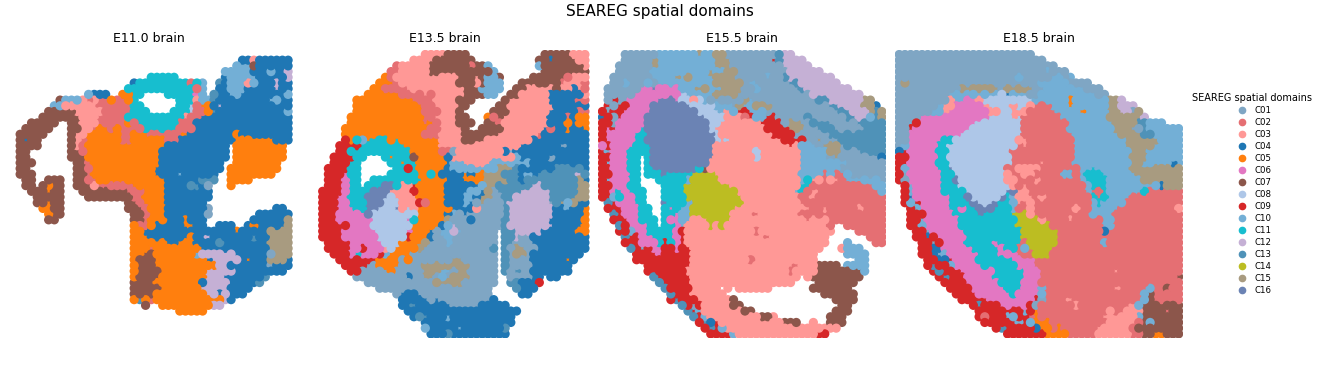

In [13]:
if domain_result is not None:
    fig, axes = spatial_panels(
        domain_result.coordinates, embeddings.slice_ids, domain_display_labels,
        palette=domain_display_palette, title="SEAREG spatial domains",
        slice_order=slice_order, **spatial_display)
    figures["spatial_domains"] = fig
    display(fig, metadata={"image/png": {"width": 900}})
    plt.close(fig)

## 13. Spot UMAP: sections, spatial domains and reference annotations

Draw three views of the saved spot UMAP, colored by section, inferred domain and reference annotation. The common coordinates let you compare section origin, chromatin domains and tissue context directly. Unknown annotations remain visible in gray.

Rerun this display cell to update colors from the saved tables.


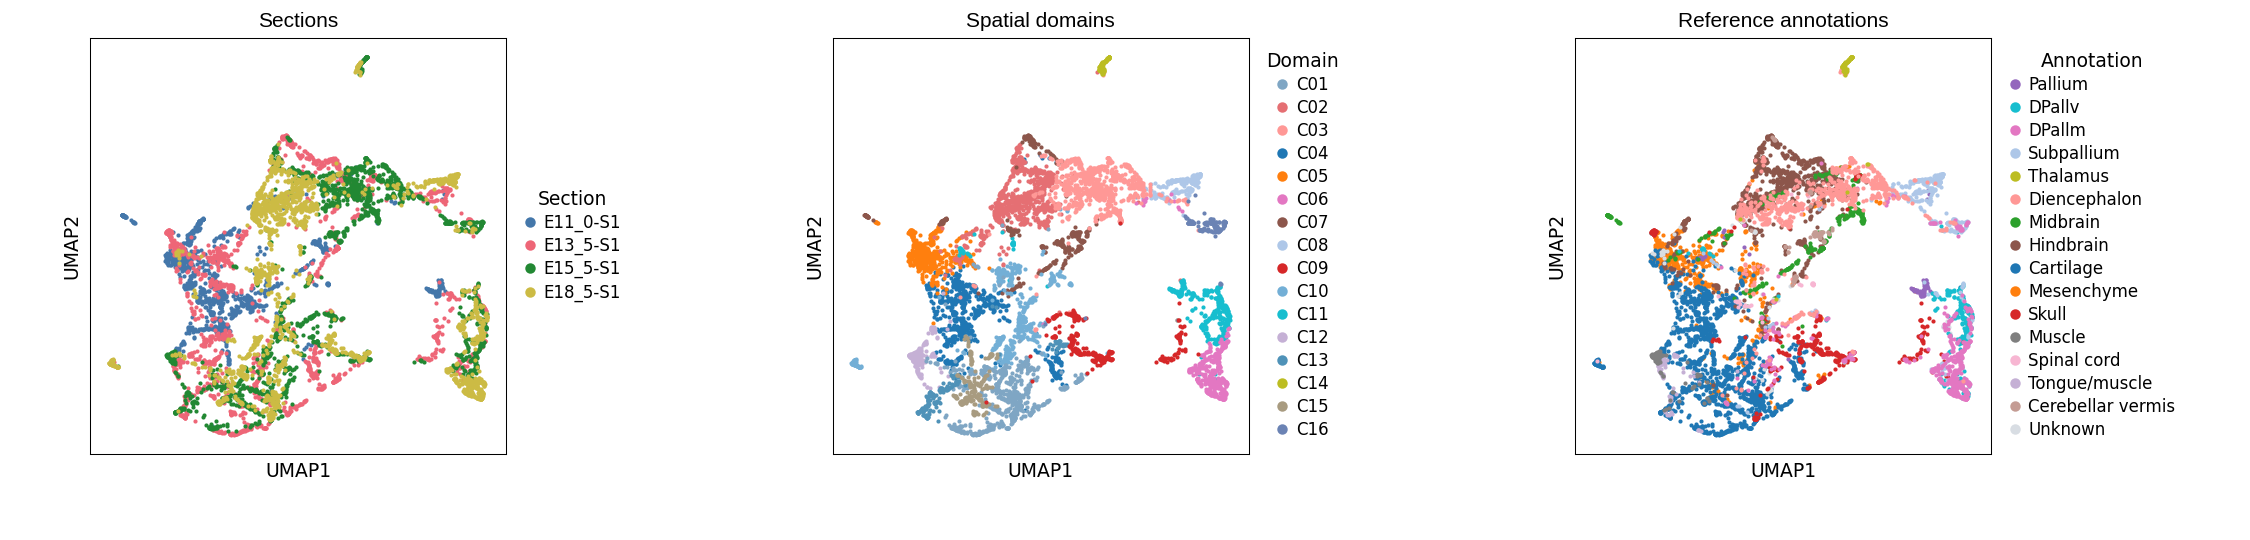

In [14]:
# Refresh only display helpers when rerunning in an existing notebook kernel.
import importlib
import seareg_tutorial_multislice as multislice_display
multislice_display = importlib.reload(multislice_display)

if spot_result is not None:
    for name in ("spot_umap_slice", "spot_umap_domain", "spot_umap_panels"):
        figures.pop(name, None)
    views = (
        ("Sections", slice_labels, slice_palette, "Section"),
        ("Spatial domains", domain_display_labels,
         domain_display_palette, "Domain"),
        ("Reference annotations", annotation_display, reference_palette, "Annotation"),
    )
    fig, axes = multislice_display.umap_panels(spot_result.table, views, point_size=4)
    figures["spot_umap_panels"] = fig
    display(fig, metadata={"image/png": {"width": 1100}})
    plt.close(fig)

## 14. Joint spot–peak UMAP

Three views share one saved joint coordinate table. Spots receive section,
domain or annotation colors. Every shared peak appears once per panel as a
gray triangle, with a shared entity legend.


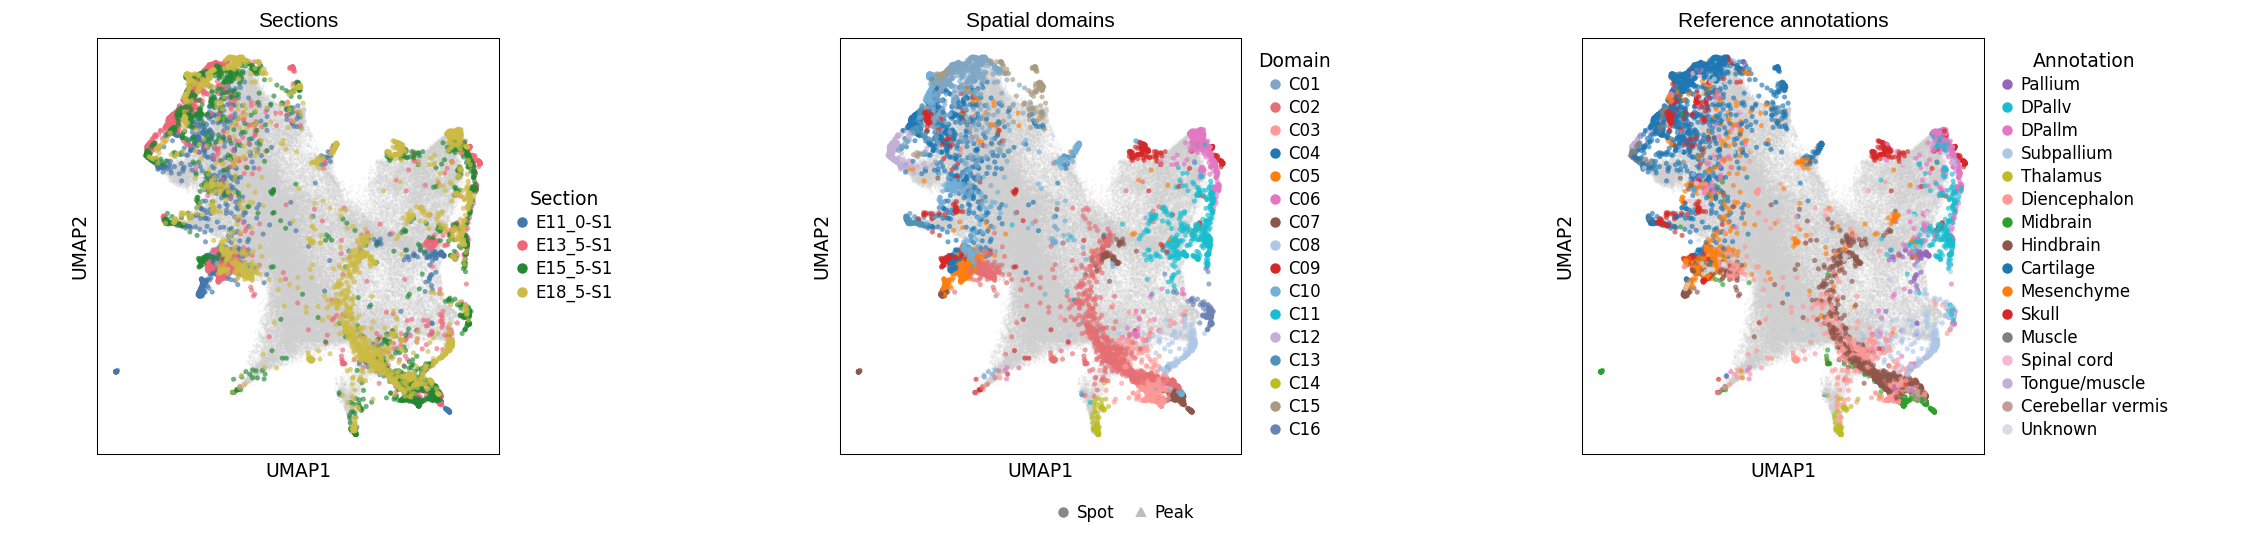

In [15]:
import importlib
import seareg_tutorial_multislice as multislice_display
multislice_display = importlib.reload(multislice_display)

if joint_result is not None:
    for name in ("joint_umap", "joint_umap_slice", "joint_umap_panels"):
        figures.pop(name, None)
    views = (
        ("Sections", slice_labels, slice_palette, "Section"),
        ("Spatial domains", domain_display_labels,
         domain_display_palette, "Domain"),
        ("Reference annotations", annotation_display, reference_palette, "Annotation"),
    )
    fig, axes = multislice_display.umap_panels(
        joint_result.table, views, joint=True, point_size=6, peak_size=1.5)
    figures["joint_umap_panels"] = fig
    display(fig, metadata={"image/png": {"width": 1100}})
    plt.close(fig)

## 15. Export figures and the execution receipt

Export the four figure families as editable PDF/SVG and PNG, and save `domain_annotation_colors.tsv` and `display_palette.json` with their display mappings.

The execution receipt identifies the inputs, embedding source, actual run mode, analysis settings and display choices. These files connect the displayed figures to the saved numerical analysis.


In [16]:
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
figure_paths = {}
for name, fig in figures.items():
    paths = plotting.save_figure(fig, FIGURE_DIR / name, dpi=450, bbox_inches=None)
    figure_paths[name] = [str(path) for path in paths]
mapping_table.to_csv(RUN_DIR / "domain_annotation_colors.tsv", sep="\t", index=False)
(RUN_DIR / "display_palette.json").write_text(json.dumps(
    {"annotations": reference_palette, "domains": domain_palette, "domain_display": domain_display_palette,
     "domain_aliases": domain_aliases, "sections": slice_palette}, indent=2))
receipt = {
    "schema_version": 1, "dataset": DATASET,
    "selected_model": "adaptive_depth_gate", "model_protocol": "two_layer_sum_adaptive_depth_gate_v1",
    "micro_formula_version": 1, "analysis_kind": "native_sr_analyze_fit", "requested_mode": RUN_MODE, "actual_mode": RUN_MODE,
    "embedding_origin": embeddings.provenance["embedding_origin"],
    "training_executed": embeddings.provenance["training_executed"],
    "embedding_source": str(EMBEDDING_DIR), "embedding_provenance": embeddings.provenance,
    "counts": {"path": str(ATAC_PATH), "sha256": file_sha256(ATAC_PATH),
               "spots": len(spot_ids), "input_peaks": counts_shape[1]},
    "annotations": {"path": str(ANNOTATIONS_PATH) if ANNOTATIONS_PATH is not None else None,
                    "sha256": file_sha256(ANNOTATIONS_PATH) if ANNOTATIONS_PATH is not None else None,
                    "known": int(annotations.annotation.ne("Unknown").sum()),
                    "unknown": int(annotations.annotation.eq("Unknown").sum()),
                    "use": "reference_maps_and_umap_views_plus_post_fit_color_matching_only"},
    "profile": {"path": str(PROFILE_PATH), "sha256": file_sha256(PROFILE_PATH)},
    "training": asdict(training_config), "execution": EXECUTION_OPTIONS,
    "training_run": str(training_run.path) if training_run is not None else None,
    "analysis": asdict(analysis_config),
    "observed_domains": domain_result.observed_k if domain_result is not None else None,
    "color_alignment": domain_result is not None,
    "domain_color_strategy": domain_color_strategy,
    "domain_color_source": domain_color_source,
    "domain_aliases": domain_aliases,
    "approved_domain_palette": {"path": str(APPROVED_DOMAIN_PALETTE_PATH) if APPROVED_DOMAIN_PALETTE_PATH else None,
        "sha256": file_sha256(APPROVED_DOMAIN_PALETTE_PATH) if APPROVED_DOMAIN_PALETTE_PATH else None,
        "applied": domain_color_source == "approved_selected"},
    "domain_color_min_fraction": domain_color_min_fraction,
    "spatial_display": spatial_display,
    "color_mapping": str(RUN_DIR / "domain_annotation_colors.tsv"),
    "figure_paths": figure_paths,
}
(RUN_DIR / "tutorial_execution.json").write_text(json.dumps(receipt, indent=2))
print(f"Saved {len(figures)} figure families and execution record to {RUN_DIR}")
display(pd.DataFrame({"figure": figure_paths.keys(), "formats": ["PNG / PDF / SVG"] * len(figure_paths)}))

Saved 4 figure families and execution record to source://train_20261031T114218Z_f0f0e6ee/result/Embryo_multislice/runs/train_20261031T114218Z_f0f0e6ee


,figure,formats
0,reference_annotations,PNG / PDF / SVG
1,spatial_domains,PNG / PDF / SVG
2,spot_umap_panels,PNG / PDF / SVG
3,joint_umap_panels,PNG / PDF / SVG


## 16. Reopen results without training or refitting

Load the saved analysis and recover its domain labels and spot/joint UMAP coordinates without training or fitting. By default, this cell reopens the current run's result.

To inspect another analysis, set `REOPEN_ANALYSIS_PATH` to its saved analysis directory. In a new kernel, set that path and run this cell directly. In the current session, reset it to `None` to return to the current run. The `loaded_*` objects support plotting from the saved results.


In [17]:
from pathlib import Path
import pandas as pd
from seareg.analysis import load_result

_existing_result = globals().get("result")
_explicit_analysis_path = globals().get("REOPEN_ANALYSIS_PATH")
if _explicit_analysis_path is not None:
    ANALYSIS_PATH = Path(_explicit_analysis_path)
elif _existing_result is not None:
    ANALYSIS_PATH = _existing_result.path
elif "RUN_DIR" in globals():
    ANALYSIS_PATH = Path(RUN_DIR) / "analysis"
else:
    raise ValueError("Set REOPEN_ANALYSIS_PATH to a saved analysis directory before running this cell.")

reopened = load_result(ANALYSIS_PATH)
saved_analysis_options = reopened.metadata["config"]
loaded_domain = reopened.domains() if saved_analysis_options["domains"] else None
loaded_spot = reopened.spot_embedding() if saved_analysis_options["spot_umap"] else None
loaded_joint = reopened.joint_embedding() if saved_analysis_options["joint"] else None
if _existing_result is not None and Path(_existing_result.path).resolve() == reopened.path:
    if loaded_domain is not None and globals().get("domain_result") is not None:
        pd.testing.assert_frame_equal(loaded_domain.labels, domain_result.labels)
    if loaded_spot is not None and globals().get("spot_result") is not None:
        pd.testing.assert_frame_equal(loaded_spot.table, spot_result.table)
    if loaded_joint is not None and globals().get("joint_result") is not None:
        pd.testing.assert_frame_equal(loaded_joint.table, joint_result.table)
print(f"Verified saved analysis: {reopened.path}")
print("Loaded the requested saved labels and UMAP coordinates without refitting.")

Verified saved analysis: source://train_20261031T114218Z_f0f0e6ee/result/Embryo_multislice/runs/train_20261031T114218Z_f0f0e6ee/analysis
Loaded the requested saved labels and UMAP coordinates without refitting.


Use the saved domain-color mapping together with the reference panels to describe where the inferred domains occur within each section.
